# **Prediksi Biaya Klaim Medis Tahunan Berdasarkan Kondisi Klinis dan Pemanfaatan Fasilitas Kesehatan**

---
Anggota:
1. Bylbiss El Haqqie (123240003)
2. Muhammad Arif Hermawan (123240063)
3. Alifah Chairul Munawar (123240234)
4. Ikhsan Wahyu Endriarto (123240241)

# **Business Understanding**

## Latar Belakang

Ketidakakuratan dalam memprediksi biaya tagihan medis tahunan nasabah menjadi ancaman serius bagi stabilitas finansial perusahaan asuransi kesehatan. Tanpa estimasi risiko medis riil yang tepat, perusahaan akan kesulitan menentukan besaran premi ideal, sehingga memicu terjadinya kesalahan penetapan harga. Penentuan premi yang terlalu rendah pada nasabah berisiko tinggi membuat perusahaan rentan menanggung pembengkakan klaim mendadak, sedangkan premi yang terlalu tinggi pada nasabah berisiko rendah mendorong mereka beralih ke kompetitor. Dampaknya, perusahaan berpotensi mengalami kerugian ganda akibat membengkaknya rasio klaim sekaligus hilangnya basis pelanggan.

## Solusi

Sebagai solusi atas permasalahan tersebut, perusahaan perlu menerapkan model prediksi yang mampu mengestimasi biaya tagihan medis nasabah secara akurat dan objektif berdasarkan histori kondisi klinis serta pemanfaatan fasilitas kesehatan. Sehingga perusahaan dapat menetapkan tarif premi secara presisi dan adil, mencegah mispricing, serta menjaga rasio klaim tetap sehat. Langkah ini efektif mempertahankan nasabah berisiko rendah melalui harga yang kompetitif sekaligus melindungi stabilitas finansial perusahaan dari risiko pembengkakan klaim mendadak.

## Import Library

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

## Memuat Dataset

In [5]:
path_to_csv = './datasets/medical_insurance.csv'
df = pd.read_csv(path_to_csv)

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

display(df.head())

,person_id,age,sex,region,urban_rural,income,education,marital_status,employment_status,household_size,dependents,bmi,smoker,alcohol_freq,visits_last_year,hospitalizations_last_3yrs,days_hospitalized_last_3yrs,medication_count,systolic_bp,diastolic_bp,ldl,hba1c,plan_type,network_tier,deductible,copay,policy_term_years,policy_changes_last_2yrs,provider_quality,risk_score,annual_medical_cost,annual_premium,monthly_premium,claims_count,avg_claim_amount,total_claims_paid,chronic_count,hypertension,diabetes,asthma,copd,cardiovascular_disease,cancer_history,kidney_disease,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
0,75722,52,Female,North,Suburban,22700.0,Doctorate,Married,Retired,3,1,27.4,Never,NaN,2,0,0,4,121.0,76.0,123.8,5.28,PPO,Bronze,1000,20,4,0,3.73,0.5714,6938.06,876.05,73.00,1,4672.59,4672.59,1,0,0,0,0,0,0,0,0,1,0,1,0,2,0,1,0,0
1,80185,79,Female,North,Urban,12800.0,No HS,Married,Employed,3,1,26.6,Never,Weekly,2,0,0,3,131.0,79.0,97.3,4.82,POS,Gold,1000,10,1,0,3.10,1.0000,1632.61,445.10,37.09,4,297.27,1189.08,2,0,0,0,0,0,0,0,0,1,1,0,0,1,0,1,1,0
2,19865,68,Male,North,Rural,40700.0,HS,Married,Retired,5,3,31.5,Never,NaN,1,0,0,4,160.0,84.0,129.5,5.51,HMO,Platinum,500,20,10,0,3.90,1.0000,7661.01,1538.02,128.17,0,0.00,0.00,3,1,0,0,0,0,1,0,0,0,1,1,0,2,1,0,1,0
3,76700,15,Male,North,Suburban,15600.0,Some College,Married,Self-employed,5,3,31.6,Never,NaN,0,0,0,1,104.0,68.0,160.3,8.50,HMO,Silver,500,20,5,0,3.89,0.2857,5130.27,820.63,68.39,0,0.00,0.00,1,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
4,92992,53,Male,Central,Suburban,89600.0,Doctorate,Married,Self-employed,2,0,30.5,Never,Daily,3,0,0,2,136.0,83.0,171.0,5.20,POS,Platinum,500,10,7,0,3.90,0.8681,1700.73,500.93,41.74,1,1002.24,1002.24,2,1,0,0,0,0,0,0,0,1,0,2,0,1,1,0,1,0


# **Data Understanding**



## Missing Values

In [6]:
print("Missing values:")
print(df.isna().sum())

print(f"\nTotal missing value dalam seluruh dataset: {df.isna().sum().sum()}")

Missing values:
person_id                          0
age                                0
sex                                0
region                             0
urban_rural                        0
income                             0
education                          0
marital_status                     0
employment_status                  0
household_size                     0
dependents                         0
bmi                                0
smoker                             0
alcohol_freq                   30083
visits_last_year                   0
hospitalizations_last_3yrs         0
days_hospitalized_last_3yrs        0
medication_count                   0
systolic_bp                        0
diastolic_bp                       0
ldl                                0
hba1c                              0
plan_type                          0
network_tier                       0
deductible                         0
copay                              0
policy_term_years     

Diketahui `alcohol_freq` memiliki missing values, dicari persentase missing value terhadap keseluruhan data

In [7]:
alcohol_freq_missing_count = df['alcohol_freq'].isna().sum()
print(f"Column: alcohol_freq")
print(f"Missing count: {alcohol_freq_missing_count}")
print(f"Missing percentage: {alcohol_freq_missing_count/len(df)*100}%")

Column: alcohol_freq
Missing count: 30083
Missing percentage: 30.083%


## Data Duplikat

In [8]:
print("Data duplikat")
print(df.duplicated().sum())

Data duplikat
0


## Outlier



In [9]:
numeric_features = df.select_dtypes(include=[np.number]).columns

skewness = df[numeric_features].skew()

for col, val in skewness.items():
    if abs(val) <= 0.5:
        print(f"Kolom '{col}' berdistribusi NORMAL (Skew: {val:.2f})")
    else:
        print(f"Kolom '{col}' berdistribusi MIRING (Skew: {val:.2f})")

Kolom 'person_id' berdistribusi NORMAL (Skew: 0.00)
Kolom 'age' berdistribusi NORMAL (Skew: 0.01)
Kolom 'income' berdistribusi MIRING (Skew: 3.39)
Kolom 'household_size' berdistribusi MIRING (Skew: 0.73)
Kolom 'dependents' berdistribusi MIRING (Skew: 1.06)
Kolom 'bmi' berdistribusi NORMAL (Skew: 0.02)
Kolom 'visits_last_year' berdistribusi MIRING (Skew: 1.60)
Kolom 'hospitalizations_last_3yrs' berdistribusi MIRING (Skew: 3.23)
Kolom 'days_hospitalized_last_3yrs' berdistribusi MIRING (Skew: 4.26)
Kolom 'medication_count' berdistribusi MIRING (Skew: 1.14)
Kolom 'systolic_bp' berdistribusi NORMAL (Skew: 0.26)
Kolom 'diastolic_bp' berdistribusi NORMAL (Skew: 0.25)
Kolom 'ldl' berdistribusi NORMAL (Skew: 0.02)
Kolom 'hba1c' berdistribusi MIRING (Skew: 2.64)
Kolom 'deductible' berdistribusi MIRING (Skew: 2.50)
Kolom 'copay' berdistribusi MIRING (Skew: 1.22)
Kolom 'policy_term_years' berdistribusi NORMAL (Skew: -0.01)
Kolom 'policy_changes_last_2yrs' berdistribusi MIRING (Skew: 4.40)
Kolom 'p

### Interquartile Range

In [10]:
q1 = df[numeric_features].quantile(0.25)
q3 = df[numeric_features].quantile(0.75)
iqr = q3 - q1

iqr_outliers = ((df[numeric_features] < (q1 - 1.5 * iqr)) | (df[numeric_features] > (q3 + 1.5 * iqr)))

iqr_summary = iqr_outliers.sum().reset_index()
iqr_summary.columns = ['Feature', 'Outlier Count']
iqr_summary['Percentage (%)'] = (iqr_summary['Outlier Count'] / len(df)) * 100

print("Pengecekan outlier menggunakan IQR")
display(iqr_summary)

Pengecekan outlier menggunakan IQR


,Feature,Outlier Count,Percentage (%)
0,person_id,0,0.000
1,age,864,0.864
2,income,6236,6.236
3,household_size,4052,4.052
4,dependents,6306,6.306
5,bmi,676,0.676
6,visits_last_year,2083,2.083
7,hospitalizations_last_3yrs,8969,8.969
8,days_hospitalized_last_3yrs,8969,8.969
9,medication_count,492,0.492


### Z-Score

In [11]:
z_score  = z_scores = np.abs(stats.zscore(df[numeric_features].fillna(df[numeric_features].median())))
z_score_outliers = pd.DataFrame(z_scores > 3, columns=numeric_features, index=df.index)

z_score_summary = pd.DataFrame({
    'Outlier Count': z_score_outliers.sum(axis=0),
    'Percentage (%)': (z_score_outliers.sum(axis=0) / len(df)) * 100
})

print("Pengecekan outlier menggunakan Z-Score")
display(z_score_summary)

Pengecekan outlier menggunakan Z-Score


,Outlier Count,Percentage (%)
person_id,0,0.000
age,131,0.131
income,1863,1.863
household_size,853,0.853
dependents,1371,1.371
bmi,295,0.295
visits_last_year,1103,1.103
hospitalizations_last_3yrs,387,0.387
days_hospitalized_last_3yrs,3915,3.915
medication_count,1591,1.591


In [12]:
total_rows = len(df)
summary_results = []

for col in numeric_features:
    unique_count = df[col].nunique()

    # dDeteksi tipe variabel sederhana
    if unique_count <= 2:
        data_type = "Binary"
    elif unique_count < 10 and (df[col] % 1 == 0).all():
        data_type = "Nominal/Ordinal"
    else:
        data_type = "Kontinu"

    iqr_outlier_count = iqr_outliers[col].sum()
    z_score_outlier_count = z_score_outliers[col].sum()

    summary_results.append({
        'Nama Kolom': col,
        'Tipe Data': data_type,
        'Total Outlier (IQR)': iqr_outlier_count,
        '% Outlier (IQR)': round((iqr_outlier_count / total_rows) * 100, 2),
        'Total Outlier (Z-Score)': z_score_outlier_count,
        '% Outlier (Z-Score)': round((z_score_outlier_count / total_rows) * 100, 2)
    })

summary_table = pd.DataFrame(summary_results)

# hitung Total Baris Unik yang Terkena Outlier
total_iqr_affected_rows = iqr_outliers.any(axis=1).sum()
total_zscore_affected_rows = z_score_outliers.any(axis=1).sum()

print(f"=== RINGKASAN TOTAL BARIS TERDAMPAK ===")
print(f"Total Baris Data: {total_rows}")
print(f"Baris dengan minimal 1 Outlier (IQR)    : {total_iqr_affected_rows} ({total_iqr_affected_rows / total_rows * 100:.2f}%)")
print(f"Baris dengan minimal 1 Outlier (Z-Score): {total_zscore_affected_rows} ({total_zscore_affected_rows / total_rows * 100:.2f}%)\n")



=== RINGKASAN TOTAL BARIS TERDAMPAK ===
Total Baris Data: 100000
Baris dengan minimal 1 Outlier (IQR)    : 71044 (71.04%)
Baris dengan minimal 1 Outlier (Z-Score): 43680 (43.68%)



## Exploratory Data Analysis

### Analisis Distribusi Target

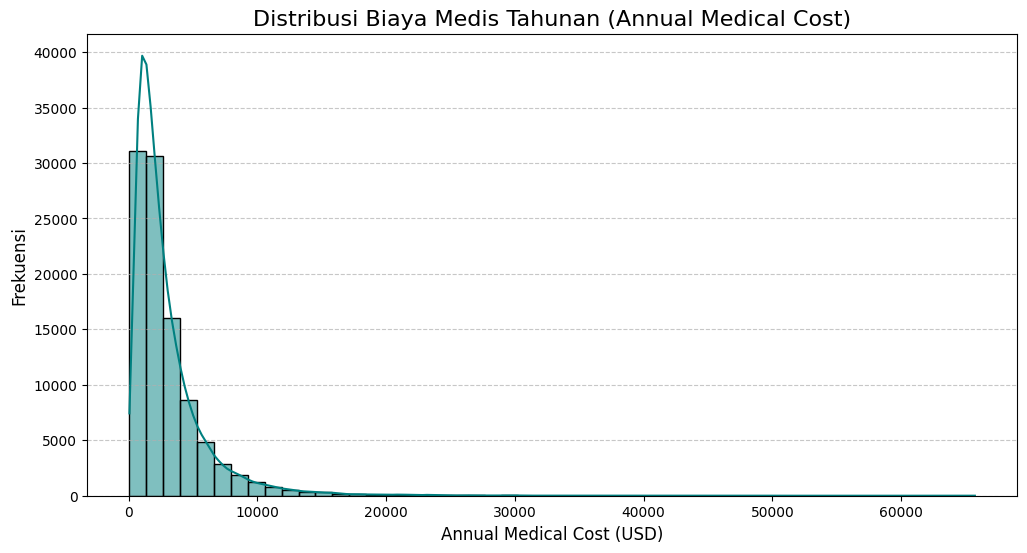


Statistik Deskriptif untuk 'annual_medical_cost':
count    100000.000000
mean       3009.451907
std        3127.462822
min          55.550000
25%        1175.117500
50%        2082.575000
75%        3707.957500
max       65724.900000
Name: annual_medical_cost, dtype: float64


In [13]:
# Visualisasi distribusi target 'annual_medical_cost'
plt.figure(figsize=(12, 6))
sns.histplot(df['annual_medical_cost'], kde=True, bins=50, color='teal')
plt.title('Distribusi Biaya Medis Tahunan (Annual Medical Cost)', fontsize=16)
plt.xlabel('Annual Medical Cost (USD)', fontsize=12)
plt.ylabel('Frekuensi', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

print("\nStatistik Deskriptif untuk 'annual_medical_cost':")
print(df['annual_medical_cost'].describe())


### Distribusi Fitur Numerik Klinis

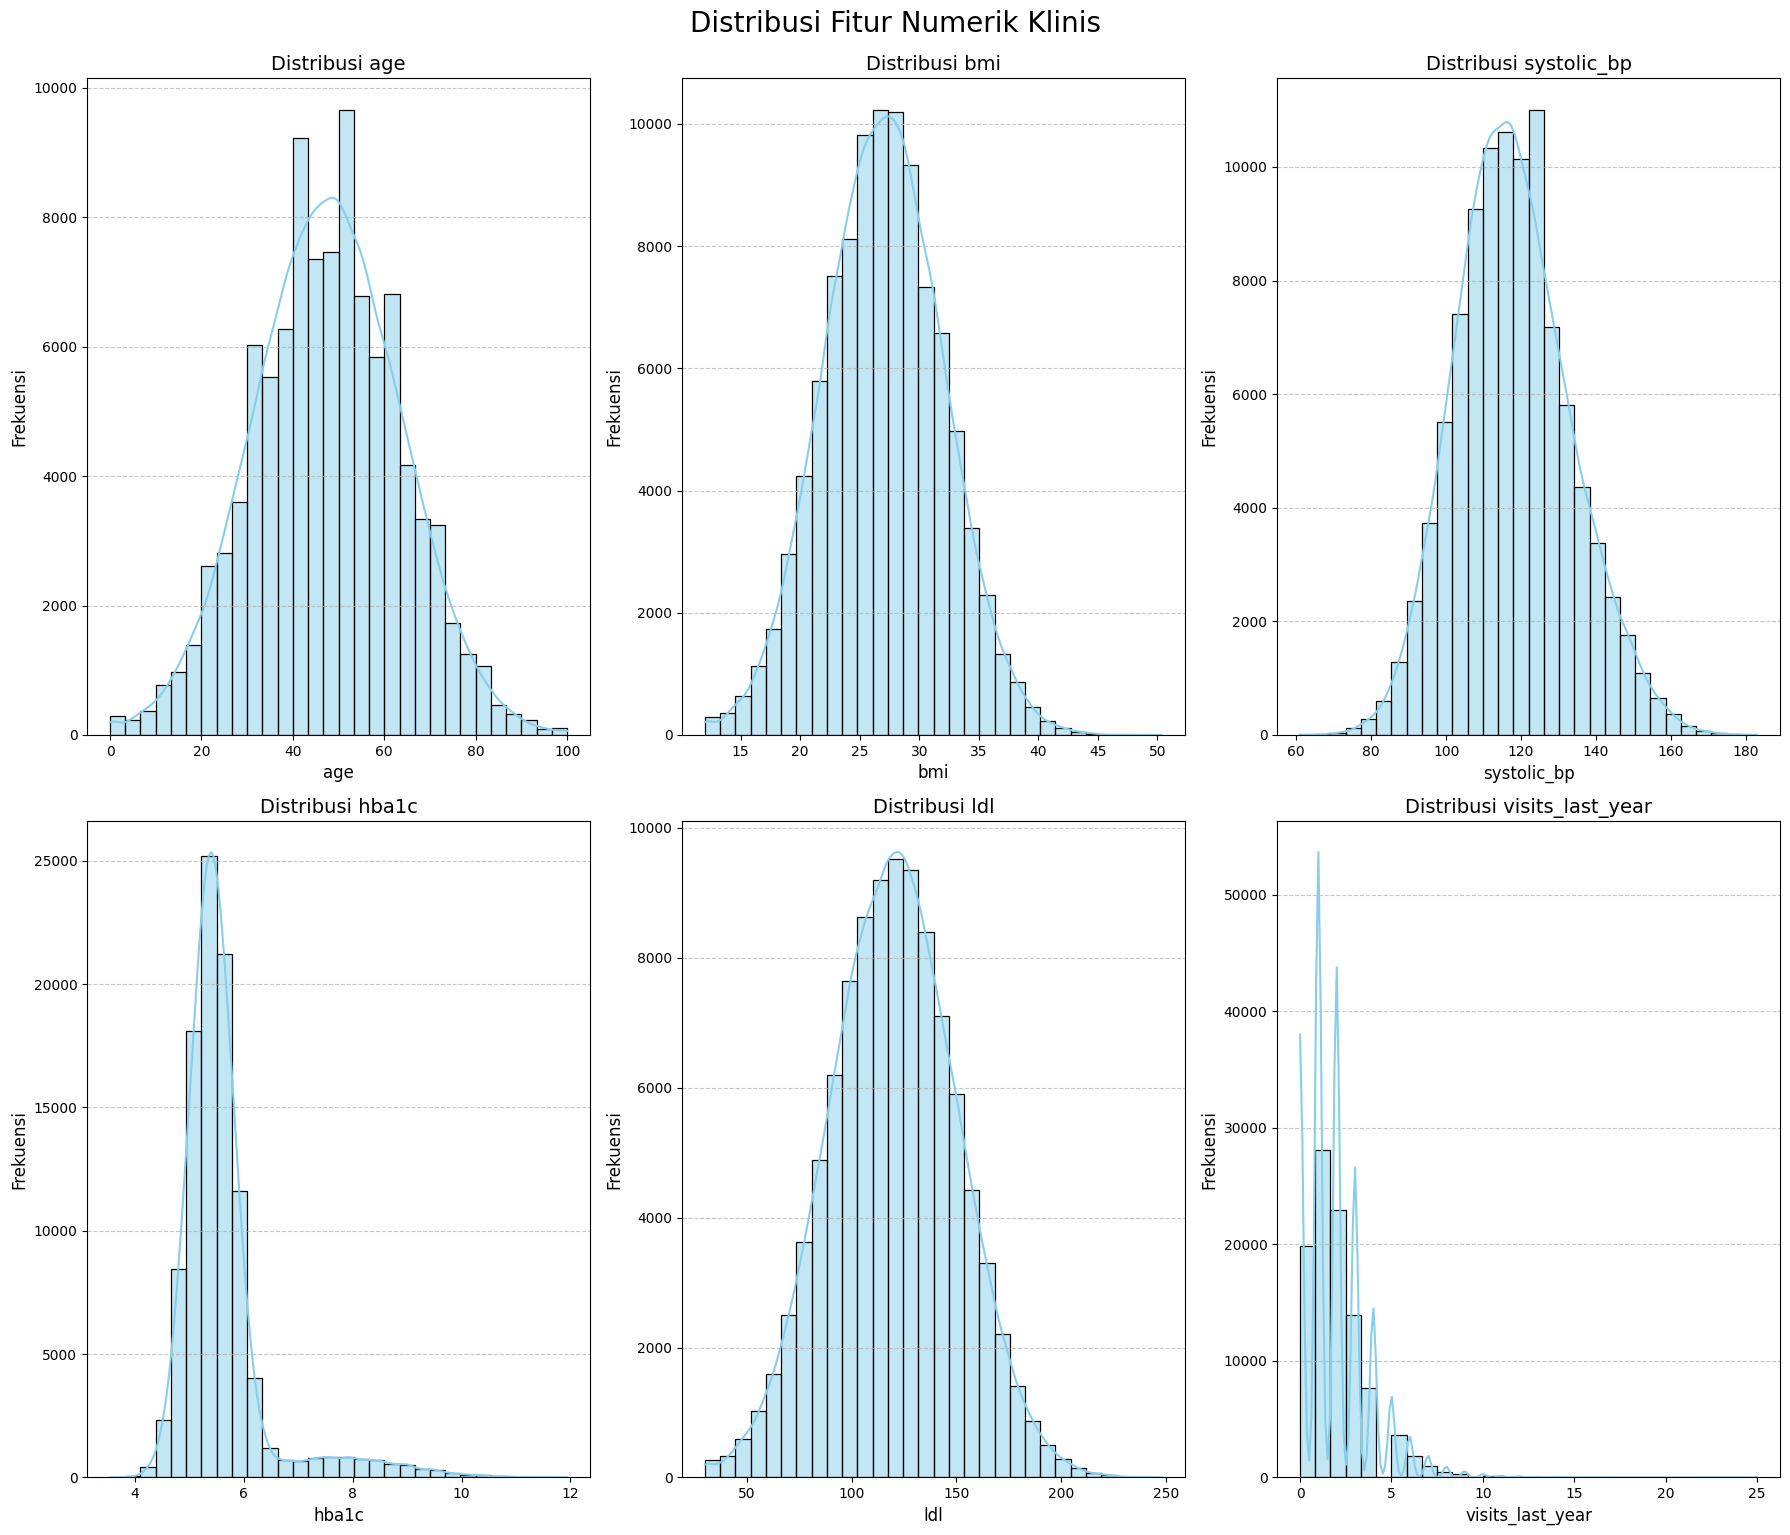

In [14]:
clinical_numeric_features = ['age', 'bmi', 'systolic_bp', 'hba1c', 'ldl', 'visits_last_year']

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 15))
axes = axes.flatten()

for i, col in enumerate(clinical_numeric_features):
    sns.histplot(df[col], kde=True, ax=axes[i], bins=30, color='skyblue')
    axes[i].set_title(f'Distribusi {col}', fontsize=14)
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel('Frekuensi', fontsize=12)
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

# Menghapus subplot yang kosong
for j in range(len(clinical_numeric_features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.suptitle('Distribusi Fitur Numerik Klinis', fontsize=20, y=1.02)
plt.show()

### Distribusi Fitur Kategorikal

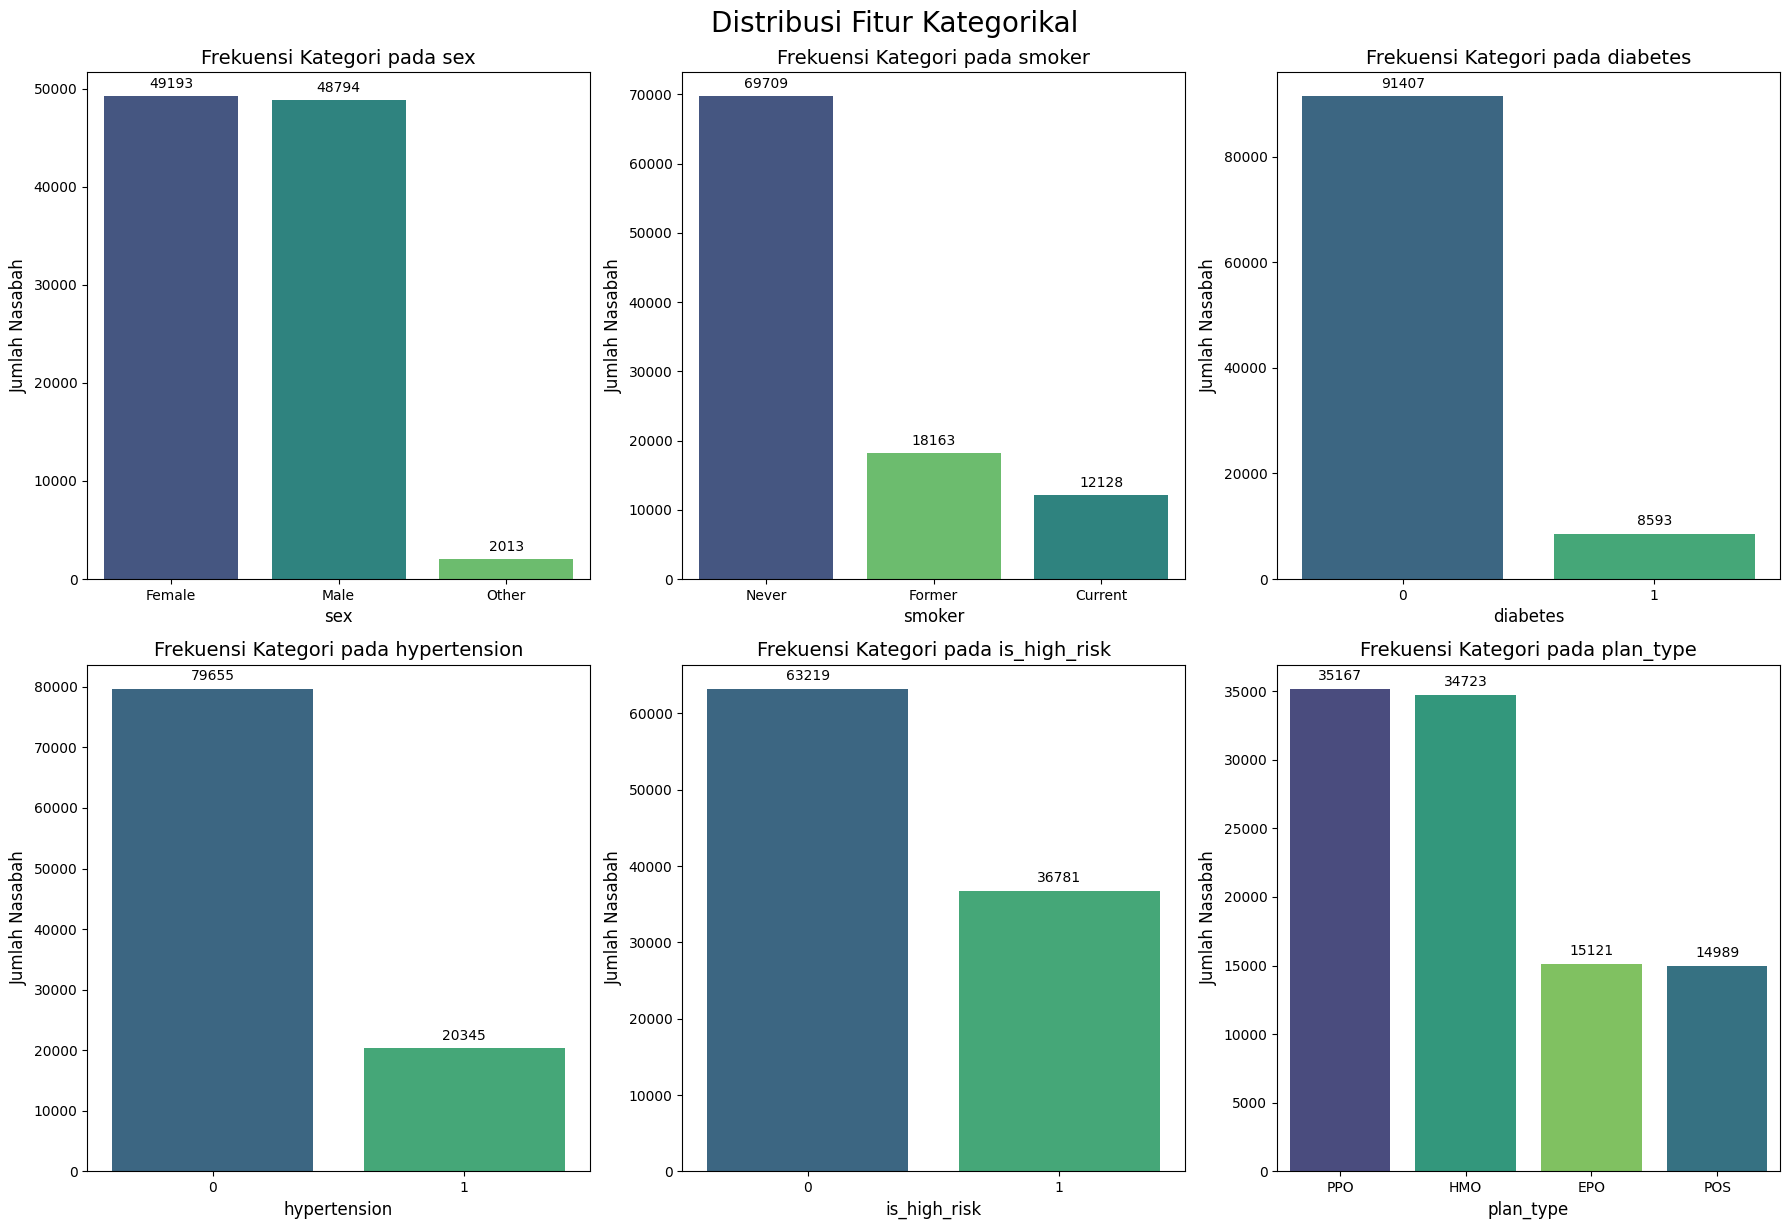

In [17]:
categorical_features = ['sex', 'smoker', 'diabetes', 'hypertension', 'is_high_risk', 'plan_type']

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(categorical_features):
    sns.countplot(
        data=df, 
        x=col, 
        hue=col, 
        ax=axes[i], 
        order=df[col].value_counts().index, 
        palette='viridis',
        legend=False 
    )
    axes[i].set_title(f'Frekuensi Kategori pada {col}', fontsize=14)
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel('Jumlah Nasabah', fontsize=12)

    for p in axes[i].patches:
        axes[i].annotate(
            f'{int(p.get_height())}', 
            (p.get_x() + p.get_width() / 2., 
            p.get_height()), 
            ha='center', va='center', 
            xytext=(0, 9), 
            textcoords='offset points'
        )

plt.tight_layout()
plt.suptitle('Distribusi Fitur Kategorikal', fontsize=20, y=1.02)
plt.show()

### Analisis Korelasi Fitur dengan Target

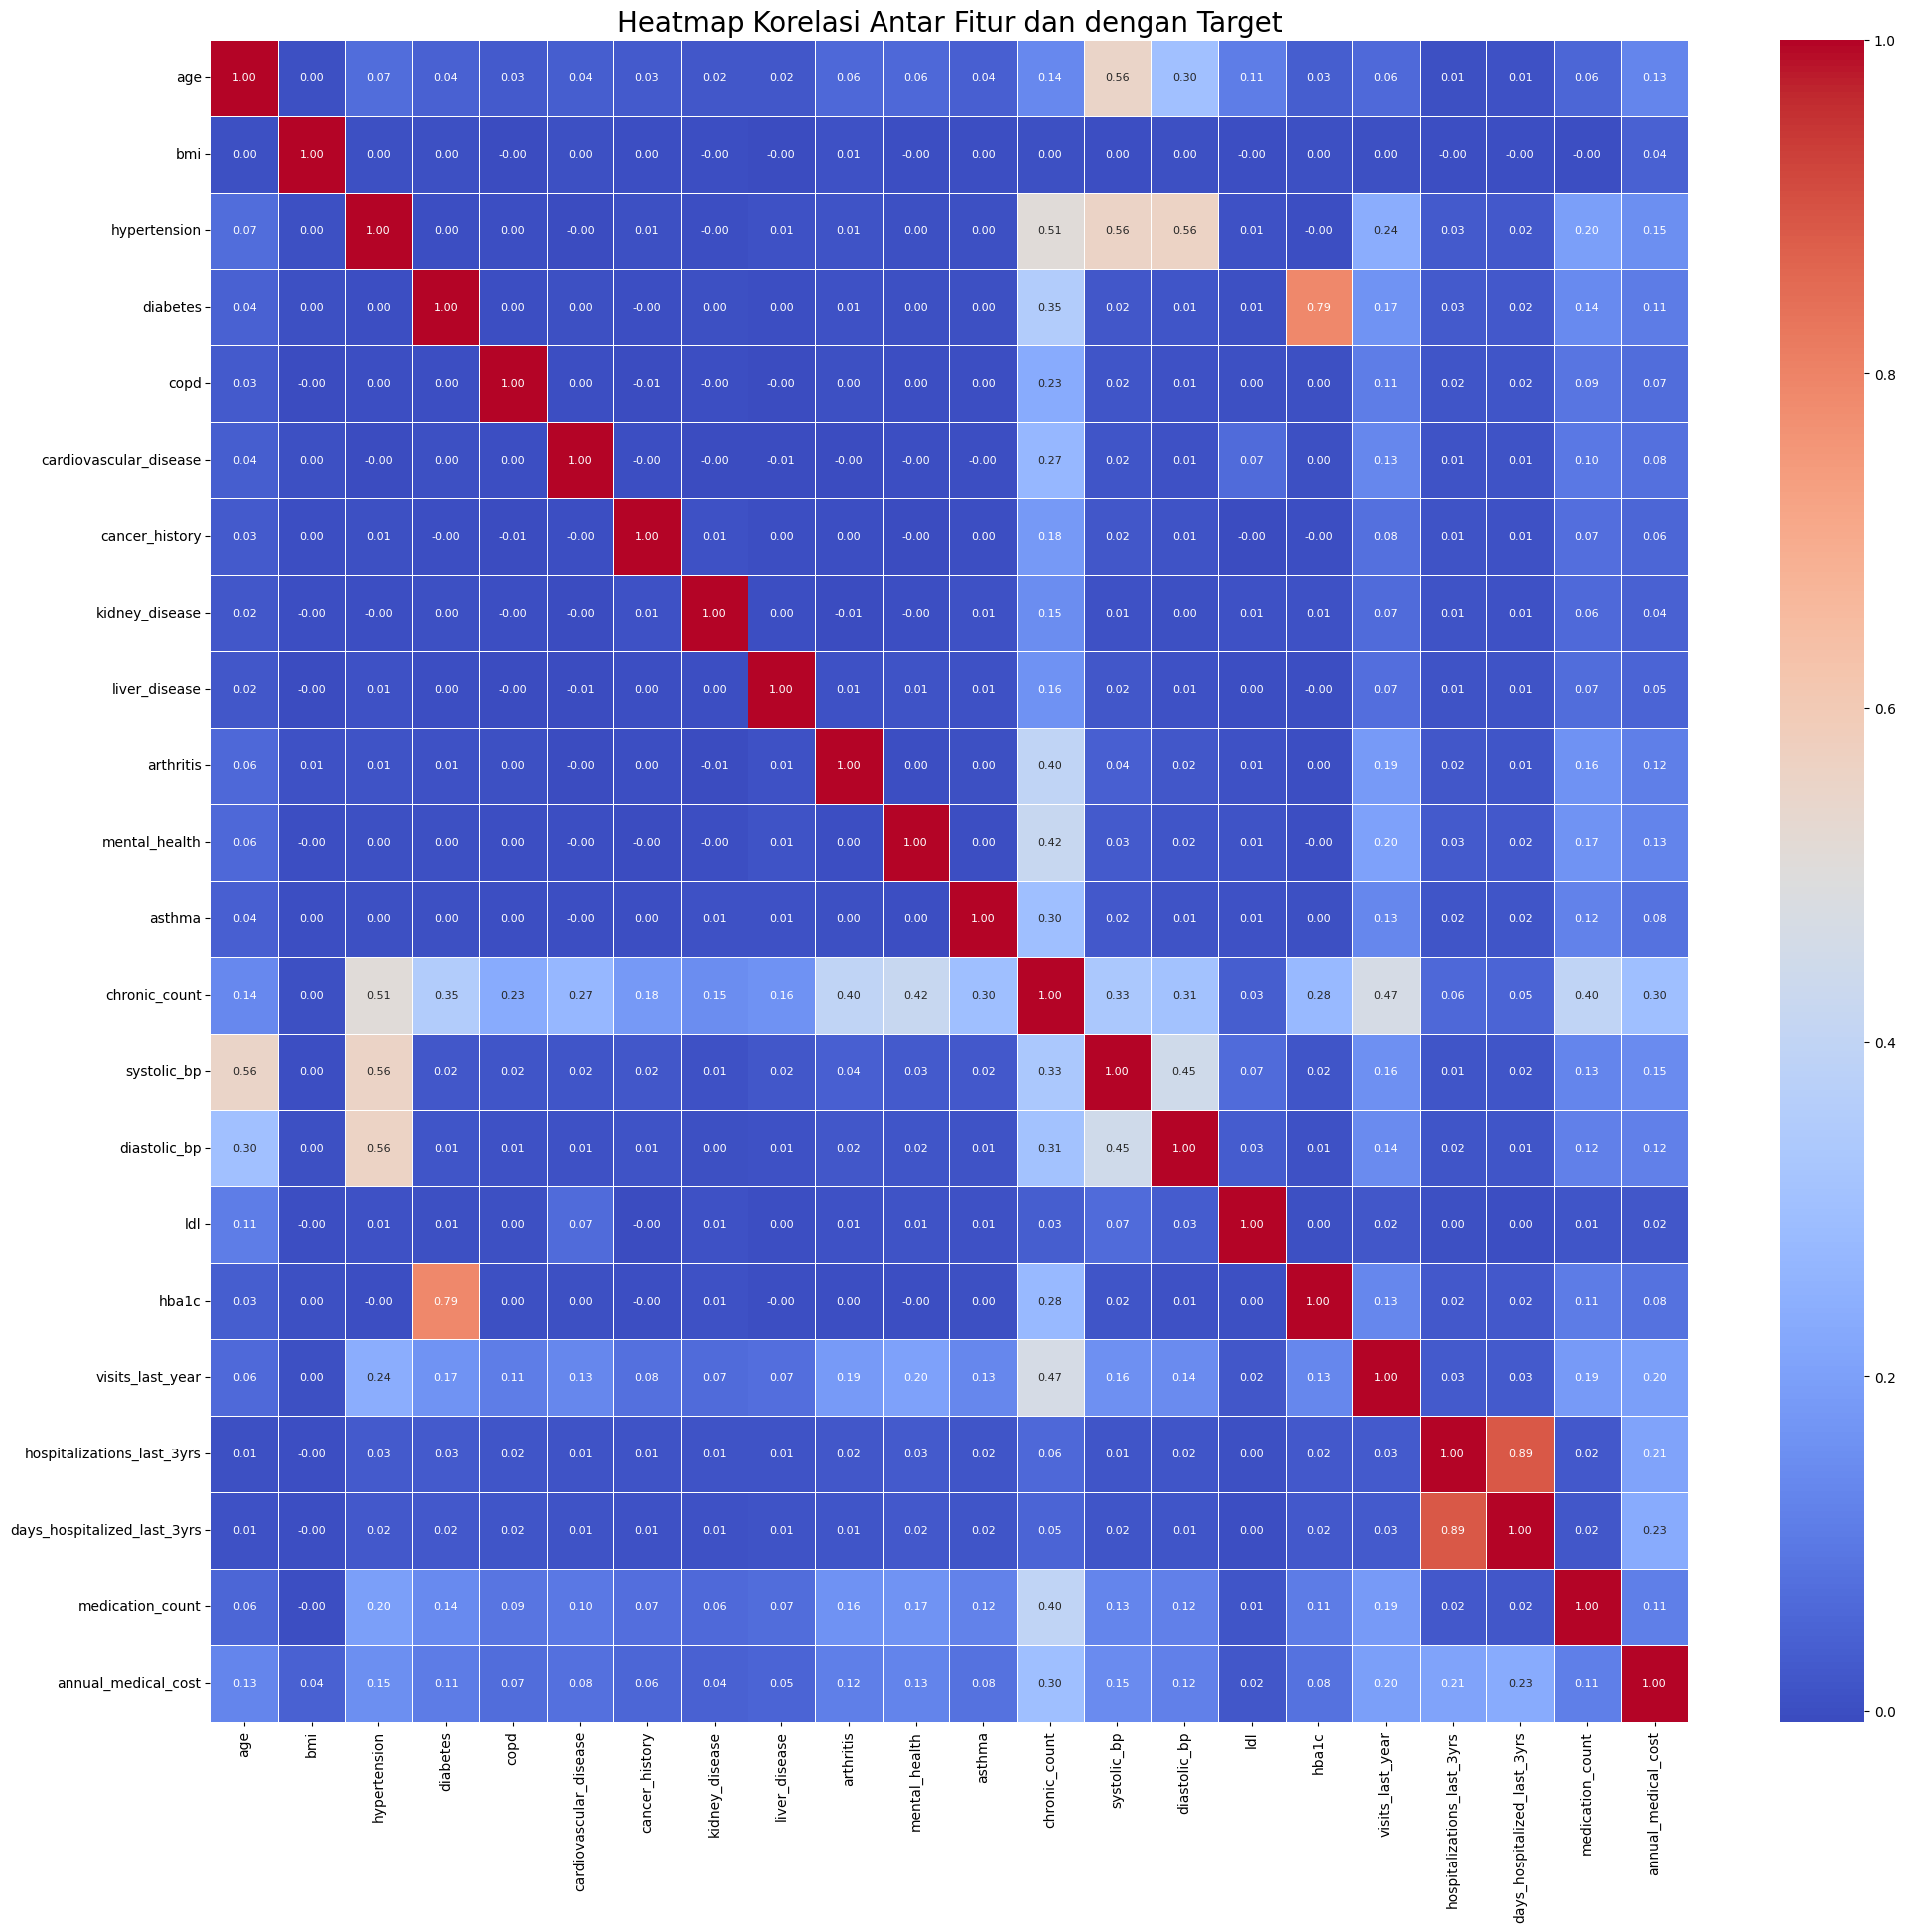


Korelasi Fitur dengan 'annual_medical_cost' (diurutkan):
annual_medical_cost            1.000000
chronic_count                  0.296720
days_hospitalized_last_3yrs    0.230246
hospitalizations_last_3yrs     0.208640
visits_last_year               0.195631
hypertension                   0.154309
systolic_bp                    0.145070
age                            0.131166
mental_health                  0.126232
diastolic_bp                   0.117647
arthritis                      0.115375
medication_count               0.113456
diabetes                       0.107373
hba1c                          0.083416
asthma                         0.080830
cardiovascular_disease         0.078515
copd                           0.069842
cancer_history                 0.055188
liver_disease                  0.050761
bmi                            0.043198
kidney_disease                 0.041799
ldl                            0.020406
Name: annual_medical_cost, dtype: float64


In [16]:
# Korelasi Linear (Heatmap)
selected_features = [
    'age', 'bmi', 'smoker', 'hypertension', 'diabetes', 'copd', 
    'cardiovascular_disease', 'cancer_history', 'kidney_disease', 
    'liver_disease', 'arthritis', 'mental_health', 'asthma', 
    'chronic_count', 'systolic_bp', 'diastolic_bp', 'ldl', 'hba1c', 
    'visits_last_year', 'hospitalizations_last_3yrs', 
    'days_hospitalized_last_3yrs', 'medication_count'
]

corr_matrix = df[selected_features + ['annual_medical_cost']].corr(numeric_only=True)

plt.figure(figsize=(24, 22))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5, annot_kws={"size": 8})
plt.title('Heatmap Korelasi Antar Fitur dan dengan Target', fontsize=20)
plt.show()

print("\nKorelasi Fitur dengan 'annual_medical_cost' (diurutkan):")
print(corr_matrix['annual_medical_cost'].sort_values(ascending=False))